<a href="https://colab.research.google.com/github/JoseLuisUgaldeM/Big-Data-Aplicado/blob/main/Copia_de_Tarea_ultimaUD.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

---

# Limpieza, Transformación y Análisis de Datos Vitivinícolas 🍷



---

Explicación del conjunto de datos elegido, cuál es su temática, su tamaño, con qué campos se relaciona y por qué puede resultar intersante

## 1. Explicación del Conjunto de Datos Elegido

- **Temática**: Mercado vitivinícola español (análisis de precios, puntuaciones, denominaciones de origen y analíticas).
- **Tamaño**: 7.752 registros unificados a partir de dos fuentes ( de 252 filas y  de 7.500 filas).
- **Campos primer conjunto de datos**: Bodega , Vino , Añada , Región , Precio , Valoración , Opiniones , Tipo , Cuerpo  y Acidez .
- **Campos segundo conjunto de datos**:
Winery, wine, year, rating, num_reviews,country, region, price, type, body, acidity
- Me ha parecido interesante ya que pertenezco profesionalmente a este sector y me gustaría aprender sobre ello un poco más.

##2. Carga de los datos
Los archivos los he adjuntado en la carpeta y habrá que cargarlos en la sesión de colab

##3. Perfilado de datos

In [49]:
import io
import pandas as pd

# 1. Carga del primer archivo
df_primera = pd.read_csv('/content/VinoEspaa.csv')

# 2. Carga del segundo archivo
with open('/content/wines_SPA.csv', 'r', encoding='utf-8-sig') as df_segunda:
    contenido_limpio = df_segunda.read().replace('""', '"')
    lineas_procesadas = []
    for linea in contenido_limpio.splitlines():
        l = linea.strip()
        if l.startswith('"') and l.endswith('"'):
            l = l[1:-1]
        lineas_procesadas.append(l)
    df_segunda = pd.read_csv(io.StringIO('\n'.join(lineas_procesadas)))

print("---  (Primeras lineas de (VinoEspaa) ---")
display(df_primera.head())

print("\n--- Primeras lineas de (wines_SPA) ---")
display(df_segunda.head())
print("\n--- Valores estadisticos del conjunto de datos (VinoEspaa)---")
print(df_primera.describe())
print("\n--- Tipos de datos de cada columna (VinoEspaa)")
print(df_primera.dtypes)
print("\n--- Tipos de datos de cada columna (wines_spa)")
print(df_segunda.dtypes)


---  (Primeras lineas de (VinoEspaa) ---


,nombre,bodega,region,uva,precio,prices_old,like,valoracion,opinion,vinificacion
0,Pago de Carraovejas 2021,Bodega Pago de Carraovejas,Ribera del Duero (España),Tempranillo/ Cabernet sauvignon/ Merlot,"37,4",No descuento,173,"4,8",125,Vino tinto
1,José Pariente Verdejo 2022,Bodegas José Pariente,Rueda (España),Verdejo,"10,5",No descuento,131,"4,5",158,Vino blanco
2,Tinto Pesquera Crianza 2020,Tinto Pesquera,Ribera del Duero (España),Tempranillo,"18,5",No descuento,103,"4,6",66,Vino tinto
3,Aalto 2021,Aalto,Ribera del Duero (España),Tempranillo,"38,7",No descuento,172,"4,8",118,Vino tinto
4,La Montesa 2020,Bodegas Palacios Remondo,Rioja (España),Garnacha/ Uvas tintas,"15,4",No descuento,385,"4,3",300,Vino tinto



--- Primeras lineas de (wines_SPA) ---


,"winery""",wine,year,rating,num_reviews,country,region,price,type,body,...,Tinto,2013,4.9,58,Espana,Toro,995,Toro Red,5,3
0,Artadi,Vina El Pison,2018,4.9,31.0,Espana,Vino de Espana,313.50,Tempranillo,4.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Vega Sicilia,Unico,2009,4.8,1793.0,Espana,Ribera del Duero,324.95,Ribera Del Duero Red,5.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Vega Sicilia,Unico,1999,4.8,1705.0,Espana,Ribera del Duero,692.96,Ribera Del Duero Red,5.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Vega Sicilia,Unico,1996,4.8,1309.0,Espana,Ribera del Duero,778.06,Ribera Del Duero Red,5.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Vega Sicilia,Unico,1998,4.8,1209.0,Espana,Ribera del Duero,490.00,Ribera Del Duero Red,5.0,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



--- Valores estadisticos del conjunto de datos (VinoEspaa)---
             like     opinion
count  252.000000  252.000000
mean    42.515873   29.492063
std     49.659034   37.473762
min      1.000000    0.000000
25%     11.000000    7.000000
50%     24.000000   16.500000
75%     54.000000   37.000000
max    385.000000  300.000000

--- Tipos de datos de cada columna (VinoEspaa)
nombre          object
bodega          object
region          object
uva             object
precio          object
prices_old      object
like             int64
valoracion      object
opinion          int64
vinificacion    object
dtype: object

--- Tipos de datos de cada columna (wines_spa)
winery"                     object
wine                        object
year                        object
rating                      object
num_reviews                float64
country                     object
region                      object
price                      float64
type                        object
body        

### 3.1 Observaciones:
Vemos que tenemos varios datos que deberían de ser numéricos y son de tipo string ( debemos de convertirlos para poder trabajar en adelante con ellos )

In [50]:
import pandas as pd

# 1. Convertir 'precio' ya que tiene una coma en vez de punto por lo que es de tipo object
df_primera['precio'] = pd.to_numeric(df_primera['precio'].astype(str).str.replace(',', '.'), errors='coerce')

# 2. Convertir 'opinion' y 'like' a valores numéricos enteros
df_primera['opinion'] = pd.to_numeric(df_primera['opinion'], errors='coerce').fillna(0).astype(int)
df_primera['like'] = pd.to_numeric(df_primera['like'], errors='coerce').fillna(0).astype(int)

# Mostrar los nuevos tipos de datos de las columnas modificadas
print("Nuevos tipos de datos en primer conjunto de datos:")
print(df_primera[['precio', 'opinion', 'like']].dtypes)

# Comprobamos que el tipo de los datos está correcto
display(df_primera[['nombre', 'precio', 'opinion', 'like']].head())

Nuevos tipos de datos en primer conjunto de datos:
precio     float64
opinion      int64
like         int64
dtype: object


,nombre,precio,opinion,like
0,Pago de Carraovejas 2021,37.4,125,173
1,José Pariente Verdejo 2022,10.5,158,131
2,Tinto Pesquera Crianza 2020,18.5,66,103
3,Aalto 2021,38.7,118,172
4,La Montesa 2020,15.4,300,385


### 3.2 Visualizaciones
Voy a utilizar la librería matplotlib para representar un histograma y un boxplot  de precios y un mapa de calor para ver la relación que existe entre el precio y el numero de opiniones y likes



Valores nulos
nombre          0
bodega          0
region          0
uva             0
precio          0
prices_old      0
like            0
valoracion      0
opinion         0
vinificacion    0
dtype: int64


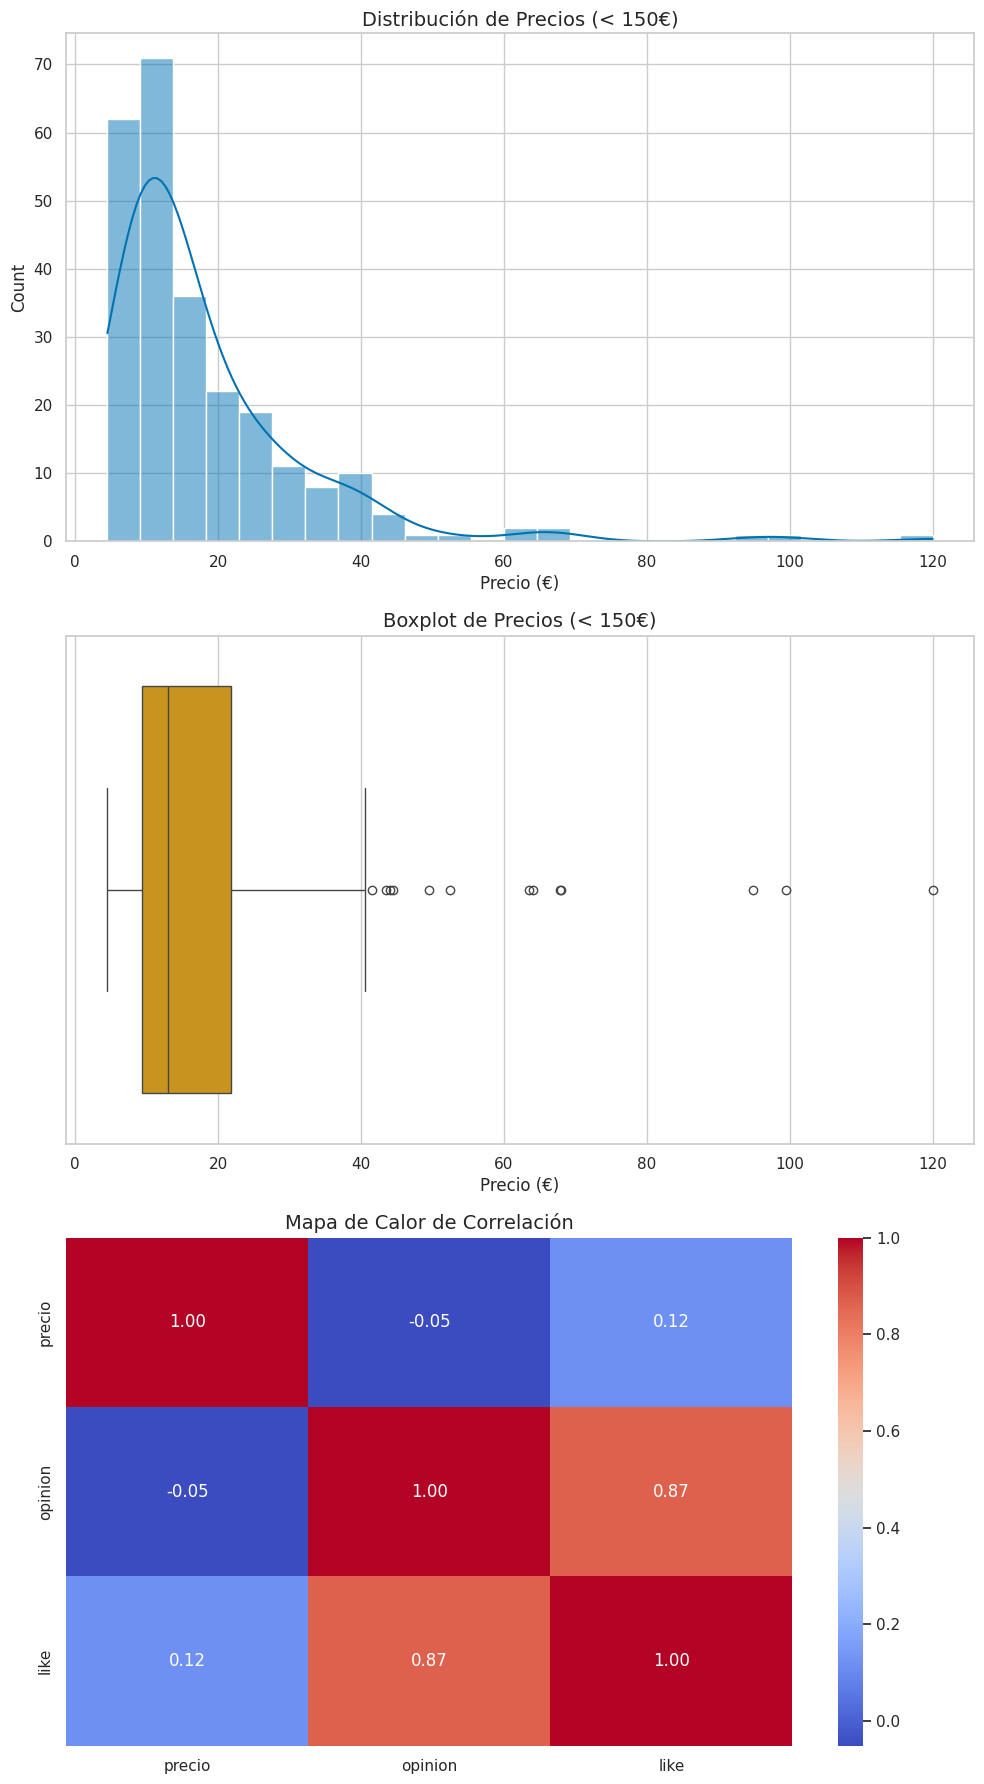

In [51]:
import matplotlib.pyplot as plt
import seaborn as sns

# Mostramos los valores nulos si es que existen
print("Valores nulos")
sns.set_theme(style="whitegrid")
print(df_primera.isnull().sum())


# Creamos una figura con 3 filas y 1 columna para apilar los gráficos verticalmente
fig, axes = plt.subplots(3, 1, figsize=(10, 18))

# Gráfico 1: Histograma de Precios
sns.histplot(df_primera["precio"], kde=True, ax=axes[0], color="#0072b2", bins=25)
axes[0].set_title("Distribución de Precios (< 150€)", fontsize=14)
axes[0].set_xlabel("Precio (€)")

# Gráfico 2: Boxplot de Precios
sns.boxplot(x=df_primera["precio"], ax=axes[1], color="#e69f00")
axes[1].set_title("Boxplot de Precios (< 150€)", fontsize=14)
axes[1].set_xlabel("Precio (€)")

# Gráfico 3: Mapa de Calor de Correlación (Usamos el dataset completo para mantener la correlación real)
df_corr = df_primera[["precio", "opinion", "like"]].dropna().corr()
sns.heatmap(df_corr, annot=True, cmap="coolwarm", fmt=".2f", ax=axes[2])
axes[2].set_title("Mapa de Calor de Correlación", fontsize=14)

plt.tight_layout()
plt.show()

###Conclusiones a la vista de los graficos
**Mirando el histograma** podemos deducir que que los precios se distribuyen por debajo de los 20 - 30 euros. A medida que nos desplazamos a la derecha el número de vinos con precios altos va cayendo. Con esto podemos decir que hay muchos vinos con precios medios y pocos con precios extremadamente altos.

**Mirando el diagrama de caja** (boxplot) podemos ver la dispersion del precio, su mediana y detectar valores atípicos.
El valor de la mediana está entre 12-15 euros y la mitad de los vinos están por debajo de ese precio.
Vemos que tenemos valores atípicos en comparacion con el resto de precios ya que algunos llegan a estar entre los 60-80 euros.

**Mirando el mapa de calor** vemos la relación lineal entre las varibles numéricas.





*   Like y opinión tienen una correlación positiva muy fuerte (0.87). Comprobamos que a mayor cantidad de opiniones registradas de un vino hay mayor cantidad de likes.
*   Precio y opinión / precio y like tienen correlaciones cercanas a 0, esto nos informa que un vino no tiene porqe tener mas opiniones o likes por su precio. Uno caro no tiene porque tener mas opiniones o likes que uno mas económico



## 4. Normalización de Datos

Escalado numérico  y StandardScaler.
Aquí pondremos todas las variables en igualdad de condiciones (las que tienen valores más altos como precio no tienen que ser mas importantes que otras que tienen valores mas pequeños coomo pueden ser valoraciones)

In [52]:
from sklearn.preprocessing import MinMaxScaler, StandardScaler
import pandas as pd
df_primera = pd.read_csv("VinoEspaa.csv")
# 1. Aseguramos que la columna 'valoracion' sea numérica reemplazando las comas por puntos
df_primera['valoracion'] = pd.to_numeric(df_primera['valoracion'].astype(str).str.replace(',', '.'), errors='coerce')
df_primera['precio'] = pd.to_numeric(df_primera['precio'].astype(str).str.replace(',', '.'), errors='coerce')
# 2. Seleccionamos las columnas numéricas
num_cols = ["precio", "opinion", "valoracion", "like"]
df_primera_clean = df_primera[num_cols].dropna().copy()

# Creamos un objeto StandardScaler y ajustamos los datos del dataframe
scaler = StandardScaler()
scaler.fit(df_primera[num_cols])

# Aplicamos el escalado al dataframe
scaled_data = scaler.transform(df_primera[num_cols])
scaled_primera_df = pd.DataFrame(scaled_data, columns=num_cols)

# Mostramos los primeros valores escalados
print("Primeros valores escalados:")
print(scaled_primera_df.head())

# Comparamos la desviación de los datos escalados con los originales
print("\nDesviación de los datos originales del dataframe")
print(df_primera[num_cols].mean())
print(df_primera[num_cols].std())

print("\nDesviaación de los datos escalados")
print(scaled_primera_df.mean())
print(scaled_primera_df.std())

# Guardamos el dataframe con los datos ya escalados
from google.colab import files
scaled_primera_df.to_csv('scaled_VinoEspaa.csv', encoding = 'utf-8-sig')
files.download('scaled_VinoEspaa.csv')

Primeros valores escalados:
     precio   opinion  valoracion      like
0  1.275810  2.553734    0.732194  2.632830
1 -0.518067  3.436102    0.256237  1.785379
2  0.015428  0.976165    0.414889  1.220412
3  1.362503  2.366564    0.732194  2.612653
4 -0.191301  7.232961   -0.061069  6.910438

Desviación de los datos originales del dataframe
precio        18.268651
opinion       29.492063
valoracion     4.338492
like          42.515873
dtype: float64
precio        15.025299
opinion       37.473762
valoracion     0.631562
like          49.659034
dtype: float64

Desviaación de los datos escalados
precio        9.384028e-17
opinion       8.458842e-17
valoracion   -2.537653e-16
like         -2.819614e-17
dtype: float64
precio        1.00199
opinion       1.00199
valoracion    1.00199
like          1.00199
dtype: float64


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

##5. Validación de datos
Comprobaremos que los datos sean correctos y completos para ello estableceremos una serie de condiciones que deben cumplir. Mostraremos los datos validados

In [53]:
import pandas as pd

# Cargamos los datos
df_primera = pd.read_csv("VinoEspaa.csv")
df_segunda = pd.read_csv("wines_SPA.csv")

# Reglas de validación
reglas = {
    'nombre': lambda x: isinstance(x, str) and len(x) > 0,  # Nombre no vacío
    'bodega': lambda x: isinstance(x, str) and len(x) > 0,  # Bodega no vacía
    'uva': lambda x: isinstance(x, str) and len(x) > 0,     # Uva no vacía
    'region': lambda x: isinstance(x, str) and len(x) > 0,  # Región no vacía
    'vinificacion': lambda x: isinstance(x, str) and len(x) > 0,  # Tipo/Vinificación no vacío
    'precio': lambda x: isinstance(x, (int, float)) and x >= 0,  # Precio no negativo
    'valoracion': lambda x: isinstance(x, (int, float)) and x >= 0,  # Valor mayor que 0
    'like': lambda x: isinstance(x, (int, float)) and x >= 0,  # Like no negativo
    'opinion': lambda x: isinstance(x, (int, float)) and x >= 0,  # Opinion no negativa
}

# Validar registros
registros_validos = pd.Series(True, index=df_primera.index)
for col, rule in reglas.items():
    # Evaluamos la regla para cada elemento de la columna
    es_valido = df_primera[col].astype(str).apply(rule)
    registros_validos = registros_validos & es_valido

    # Si hay filas inválidas, les asignamos None
    invalid_rows = df_primera[~es_valido].index
    if len(invalid_rows) > 0:
        df_primera.loc[invalid_rows, col] = None

print(f"Registros válidos: {registros_validos.sum()} de {len(df_primera)}")
display(df_primera)

Registros válidos: 0 de 252


,nombre,bodega,region,uva,precio,prices_old,like,valoracion,opinion,vinificacion
0,Pago de Carraovejas 2021,Bodega Pago de Carraovejas,Ribera del Duero (España),Tempranillo/ Cabernet sauvignon/ Merlot,None,No descuento,NaN,None,NaN,Vino tinto
1,José Pariente Verdejo 2022,Bodegas José Pariente,Rueda (España),Verdejo,None,No descuento,NaN,None,NaN,Vino blanco
2,Tinto Pesquera Crianza 2020,Tinto Pesquera,Ribera del Duero (España),Tempranillo,None,No descuento,NaN,None,NaN,Vino tinto
3,Aalto 2021,Aalto,Ribera del Duero (España),Tempranillo,None,No descuento,NaN,None,NaN,Vino tinto
4,La Montesa 2020,Bodegas Palacios Remondo,Rioja (España),Garnacha/ Uvas tintas,None,No descuento,NaN,None,NaN,Vino tinto
...,...,...,...,...,...,...,...,...,...,...
247,Canals & Munné Dionysus Brut Nature Eco 2021,Canals & Munné,DO Cava (España),Xarel·lo/ Chardonnay/ Macabeo,None,No descuento,NaN,None,NaN,Cava
248,Guímaro 2022,Guímaro,Ribeira Sacra (España),Mencía/ Caiño tinto/ Sousón,None,No descuento,NaN,None,NaN,Vino tinto
249,La Mateo Colección de Familia Vendimia 2020,Bodegas D. Mateos,Rioja (España),Tempranillo/ Garnacha/ Graciano,None,No descuento,NaN,None,NaN,Vino tinto
250,Adhuc Tempus Albariño 2022,Vinos Adhuc Tempus,Rías Baixas (España),Albariño,None,No descuento,NaN,None,NaN,Vino blanco


## 6. Integración y Enriquecimiento de Datos

Fusión en  y creación de nuevas características ( y ).

In [54]:
import io
import pandas as pd
import unicodedata
from google.colab import files

def normalizar_texto(texto):
    if not isinstance(texto, str):
        return ""
    # 1. Convertir a minúsculas y eliminar espacios
    texto = texto.lower().strip()
    # 2. Eliminar contenido entre paréntesis, por ejemplo " (españa)"
    if '(' in texto:
        texto = texto.split('(')[0].strip()
    # 3. Eliminar acentos y tildes
    texto = ''.join(
        c for c in unicodedata.normalize('NFD', texto)
        if unicodedata.category(c) != 'Mn'
    )
    return texto

# 1. Cargamos el primer dataset
df_primera = pd.read_csv("VinoEspaa.csv")

# 2. Cargamos el segundo dataset limpiando las comillas
with open('wines_SPA.csv', 'r', encoding='utf-8-sig') as archivo_segunda:
    contenido_limpio = archivo_segunda.read().replace('""', '"')
    lineas_procesadas = []
    for linea in contenido_limpio.splitlines():
        l = linea.strip()
        if l.startswith('"') and l.endswith('"'):
            l = l[1:-1]
        lineas_procesadas.append(l)
    df_segunda = pd.read_csv(io.StringIO('\n'.join(lineas_procesadas)))

# 3. Normalizamos de forma avanzada la columna 'region' en ambos DataFrames
df_primera['region_norm'] = df_primera['region'].apply(normalizar_texto)
df_segunda['region_norm'] = df_segunda['region'].apply(normalizar_texto)

# 4. Unimos los datasets utilizando la columna normalizada limpia
primeraMasSegunda = pd.merge(df_primera, df_segunda,left_on='region_norm', right_on='region_norm' )

# Eliminamos la columna region_norm
primeraMasSegunda = primeraMasSegunda.drop(columns=['region_norm'])

# Mostramos el resultado de la unión y el numero de filas obtenidas
print(f"¡Unión completada con éxito! Filas obtenidas: {len(primeraMasSegunda)}")
display(primeraMasSegunda.head())

# 5. Guardamos el DataFrame resultante y lo descargamos
primeraMasSegunda.to_csv('primeraMasSegunda.csv', encoding='utf-8-sig')
files.download('primeraMasSegunda.csv')

¡Unión completada con éxito! Filas obtenidas: 178882


,nombre,bodega,region_x,uva,precio,prices_old,like,valoracion,opinion,vinificacion,...,Tinto,2013,4.9,58,Espana,Toro,995,Toro Red,5,3
0,Pago de Carraovejas 2021,Bodega Pago de Carraovejas,Ribera del Duero (España),Tempranillo/ Cabernet sauvignon/ Merlot,"37,4",No descuento,173,"4,8",125,Vino tinto,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Pago de Carraovejas 2021,Bodega Pago de Carraovejas,Ribera del Duero (España),Tempranillo/ Cabernet sauvignon/ Merlot,"37,4",No descuento,173,"4,8",125,Vino tinto,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Pago de Carraovejas 2021,Bodega Pago de Carraovejas,Ribera del Duero (España),Tempranillo/ Cabernet sauvignon/ Merlot,"37,4",No descuento,173,"4,8",125,Vino tinto,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Pago de Carraovejas 2021,Bodega Pago de Carraovejas,Ribera del Duero (España),Tempranillo/ Cabernet sauvignon/ Merlot,"37,4",No descuento,173,"4,8",125,Vino tinto,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Pago de Carraovejas 2021,Bodega Pago de Carraovejas,Ribera del Duero (España),Tempranillo/ Cabernet sauvignon/ Merlot,"37,4",No descuento,173,"4,8",125,Vino tinto,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 7. Agregación de datos
Recopilaremos la información de varios registro y la mostraremos en un formato agrupado *(equivalente  a group by)*

In [56]:
import pandas as pd

# Aseguramos que las columnas de precio y valoración sean numéricas en el DataFrame unificado
primeraMasSegunda['price'] = pd.to_numeric(primeraMasSegunda['price'], errors='coerce')
primeraMasSegunda['rating'] = pd.to_numeric(primeraMasSegunda['rating'], errors='coerce')
primeraMasSegunda['num_reviews'] = pd.to_numeric(primeraMasSegunda['num_reviews'], errors='coerce')

print("--- Resumen estadístico por Bodega (Precio Medio y Puntuación Media) ---")

agrupado_bodega = primeraMasSegunda.groupby('bodega').agg(
    total_vinos=('nombre', 'count'),
    precio_promedio=('price', 'mean'),
    valoracion_promedio=('rating', 'mean'),
    total_opiniones=('num_reviews', 'sum')
).reset_index()

# Renombramos la columna para que quede más clara en el reporte
agrupado_bodega = agrupado_bodega.rename(columns={'region_x': 'region'})

# Ordenamos por precio promedio de mayor a menor
agrupado_bodega = agrupado_bodega.sort_values(by='precio_promedio', ascending=False)

display(agrupado_bodega)

--- Resumen estadístico por Bodega (Precio Medio y Puntuación Media) ---


,bodega,total_vinos,precio_promedio,valoracion_promedio,total_opiniones
83,Celler Carles Andreu,6,164.543333,4.383333,1154.0
78,Canopy,3,121.986667,4.300000,97.0
1,Aalto,1412,109.007793,4.296530,796622.0
13,Bodega Pago de Carraovejas,1412,109.007793,4.296530,796622.0
11,Bodega Bela,1412,109.007793,4.296530,796622.0
...,...,...,...,...,...
118,Marqués de Vizhoja,252,18.098681,4.215079,104242.0
138,Vinos Adhuc Tempus,252,18.098681,4.215079,104242.0
131,Santiago Ruiz,252,18.098681,4.215079,104242.0
20,Bodegas Atalaya,7,17.555714,4.314286,7112.0


## 8. Reducción de datos


Varianza explicada por PC1: 47.21%
Varianza explicada por PC2: 27.52%
Varianza acumulada: 74.73%



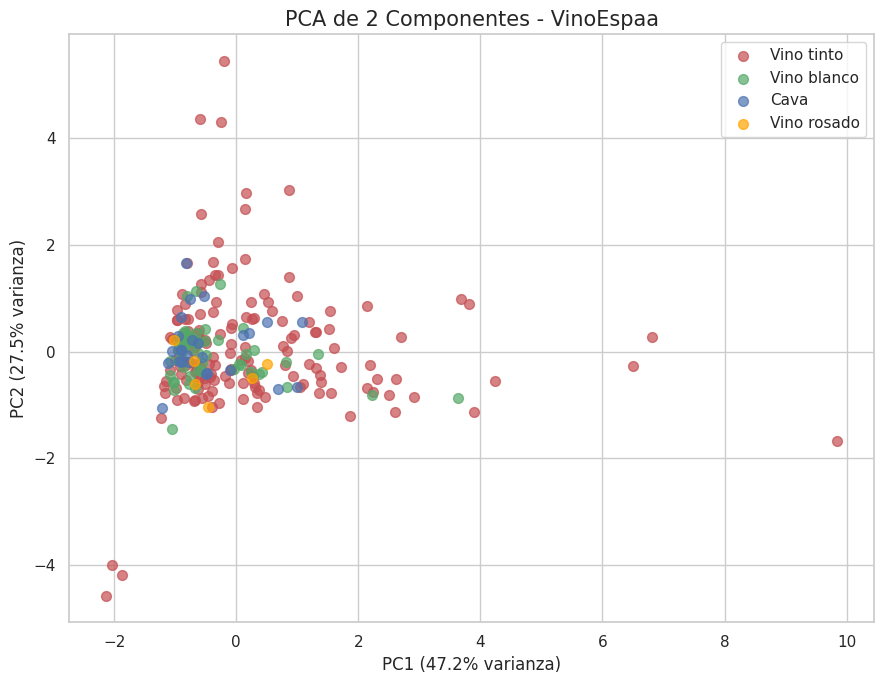

In [57]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# 1. Cargar el dataset VinoEspaa.csv de forma robusta
df = pd.read_csv('/content/VinoEspaa.csv', encoding='utf-8', encoding_errors='replace')

# 2. Preprocesamiento: Convertir columnas numéricas con coma a float
df['precio_num'] = df['precio'].astype(str).str.replace(',', '.').astype(float)
df['valoracion_num'] = df['valoracion'].astype(str).str.replace(',', '.').astype(float)
df['like_num'] = df['like'].astype(float)
df['opinion_num'] = df['opinion'].astype(float)

# 3. Separar características (X) y variable objetivo (y)
num_cols = ['precio_num', 'valoracion_num', 'like_num', 'opinion_num']
X = df[num_cols].values
y = df['vinificacion'].values

# 4. Estandarizar las características (StandardScaler)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 5. Aplicar PCA (Reducción a 2 componentes principales)
pca = PCA(n_components=2)
principal_components = pca.fit_transform(X_scaled)

# 6. Crear un nuevo DataFrame con los componentes principales y la variable objetivo
df_pca = pd.DataFrame(data=principal_components, columns=['PC1', 'PC2'])
df_pca['target'] = y

# Mostrar varianza explicada por cada componente
print(f'Varianza explicada por PC1: {pca.explained_variance_ratio_[0]*100:.2f}%')
print(f'Varianza explicada por PC2: {pca.explained_variance_ratio_[1]*100:.2f}%')
print(f'Varianza acumulada: {sum(pca.explained_variance_ratio_)*100:.2f}%\n')

# 7. Graficar los componentes principales
fig = plt.figure(figsize=(9, 7))
ax = fig.add_subplot(1, 1, 1)
ax.set_xlabel('PC1 (47.2% varianza)', fontsize=12)
ax.set_ylabel('PC2 (27.5% varianza)', fontsize=12)
ax.set_title('PCA de 2 Componentes - VinoEspaa', fontsize=15)

targets = ['Vino tinto', 'Vino blanco', 'Cava', 'Vino rosado']
colors = ['r', 'g', 'b', 'orange']

for target, color in zip(targets, colors):
    indicesToKeep = df_pca['target'] == target
    ax.scatter(
        df_pca.loc[indicesToKeep, 'PC1'],
        df_pca.loc[indicesToKeep, 'PC2'],
        c=color,
        s=50,
        alpha=0.7,
        label=target
    )

ax.legend(targets)
ax.grid(True)
plt.tight_layout()
plt.show()

## 9. Validación cruzada

In [ ]:
# Import necessary libraries
import pandas as pd
from sklearn.model_selection import cross_val_score
from sklearn.tree import DecisionTreeClassifier

# Load data
names = ['release_year', 'runtime', 'seasons', 'imdb_score', 'imdb_votes', 'tmdb_popularity', 'tmdb_score']
titlesdf = pd.read_csv("datashets/titles.csv", names=names)

# Separate features and target variable
X = titlesdf.iloc[:, :-1].values
y = titlesdf.iloc[:, -1].values

# Initialize a decision tree classifier
classifier = DecisionTreeClassifier()

# Perform 10-fold cross-validation
scores = cross_val_score(classifier, X.astype(float), y, cv=10)

# Print the accuracy of each fold and the mean accuracy
for i, score in enumerate(scores):
  print("Accuracy of fold %d: %.2f" % (i+1, score))
  print("Mean Accuracy: %.2f%%" % (scores.mean()*100))

## 10. Prueba de hipótesis
¿En qué consiste una prueba de hipótesis?
Una prueba de hipótesis es el método científico y estadístico que responde a la pregunta de si la diferencia entre dos grupos es real o fruto del azar.

In [ ]:
import pandas as pd
from scipy import stats

# 1. Cargamos el dataset
df_primera = pd.read_csv('/content/VinoEspaa.csv')

# Convertimos los precios a valores numéricos reemplazando comas por puntos
df_primera['precio'] = pd.to_numeric(df_primera['precio'].astype(str).str.replace(',', '.'), errors='coerce')

# Normalizamos la columna region a minúsculas y quitamos espacios
df_primera['region_clean'] = df_primera['region'].astype(str).str.lower().str.strip()

# Filtramos usando búsquedas parciales para asegurar que encuentre las regiones sin importar caracteres especiales o tildes
precios_ribera = df_primera[df_primera['region_clean'].str.contains('ribera', na=False)]['precio'].dropna()
precios_rioja = df_primera[df_primera['region_clean'].str.contains('rioja', na=False)]['precio'].dropna()

# Calculamos la media de cada uno de los precios
media_ribera = precios_ribera.mean()
media_rioja = precios_rioja.mean()

# Mostramos por pantalla las cantidades y los resultados de las medias
print(f'Vinos de Ribera del Duero encontrados: {len(precios_ribera)}')
print(f'Vinos de Rioja encontrados: {len(precios_rioja)}')
print(f'Media de los precios de los vinos de la Ribera del Duero: {media_ribera:.2f} €' if not pd.isna(media_ribera) else 'Media de los precios de los vinos de la Ribera del Duero: No encontrado/Sin datos')
print(f'Media de los precios de los vinos de la Rioja: {media_rioja:.2f} €' if not pd.isna(media_rioja) else 'Media de los precios de los vinos de la Rioja: No encontrado/Sin datos')

# 2. Obtenemos los valores para determinar la prueba
t_stat, p_val = stats.ttest_ind(precios_ribera, precios_rioja, equal_var=False)
print(f"Estadístico t: {t_stat:.4f}")
print(f"p-valor: {p_val:.4e}")

### CONCLUSIÓN
Como el p-valor es mayor de 0.05 no se descarta la hipótesis nula. La pequeña diferencia de precios que existe entre las dos regiones puede no ser estadísticamente significativa (real) y deberse al azar.